<a href="https://colab.research.google.com/github/kr7/dskim1600/blob/main/%C3%9Cbung_Neuronale_Netzwerke_mit_L%C3%B6sungen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from google.colab import widgets

**Laden und Anzeigen der Daten**

Wir werden ein neuronales Netzwerk für die Erkennung handgeschriebenen Ziffer trainieren. Die ursprüngliche Auflösung der Bilder ist 16x16, aber die Auflösung wird auf 8x8 reduziert, damit die Berechnungen schneller ausgeführt werden können.

In [ ]:
data = np.loadtxt('https://archive.ics.uci.edu/ml/machine-learning-databases/semeion/semeion.data')

In [ ]:
original_img_size = (16, 16)
new_img_size = (8,8)

data_8x8 = []
for i in range(len(data)):
  img_16x16 = np.reshape(data[i,0:256], original_img_size)
  img_8x8 = cv2.resize(img_16x16, new_img_size)
  img_8x8 = np.reshape(img_8x8, (64))
  data_8x8.append( img_8x8 )

data_8x8 = np.array(data_8x8)

Einige Bilder werden gezeigt:

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

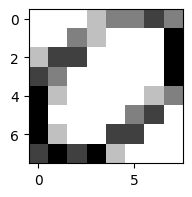

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

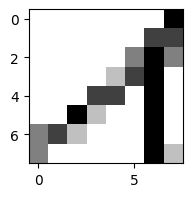

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

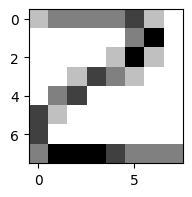

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

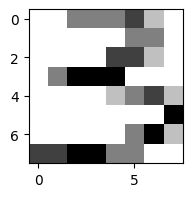

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

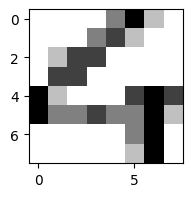

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

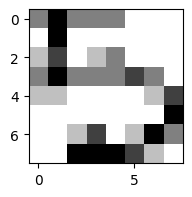

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

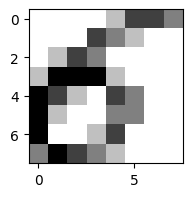

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

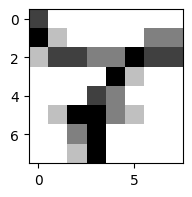

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

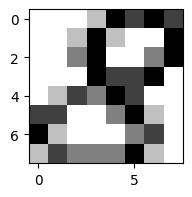

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

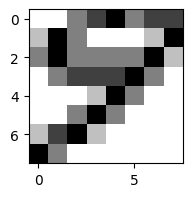

<IPython.core.display.Javascript object>

In [ ]:
tb = widgets.TabBar([str(i) for i in range(10)], location='top')
for i in range(10):
  with tb.output_to(i):
    an_image = np.reshape(data_8x8[200+i*20], new_img_size )
    plt.figure(figsize=(2,2))
    plt.imshow(1-an_image, cmap='gray', vmin=0, vmax=1)
    plt.show()

Der Datensatz wird in Trainings- und Testdatensatz geteilt.

In [ ]:
train_data = data_8x8[:1093,0:64]
train_labels = data[:1093,256:266]
test_data = data_8x8[1093:,0:64]
test_labels = data[1093:,256:266]

**Die Definition des Modells**

In [ ]:
class DigitRecognizer(nn.Module):
    def __init__(self):
        super(DigitRecognizer, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.out(x)
        return x

**Trainingsschleife**

(siehe auch: Vorlesungsfolien)

In [ ]:
train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  #print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

**Die Genuaigkeit des Netzwerks**

Der Anteil der richtig klassifizierten Instanzen wird bestimmt.

In [ ]:
def eval_net(net):
  test_dataset = torch.utils.data.TensorDataset(
        torch.Tensor(test_data), torch.Tensor(test_labels))
  testloader = torch.utils.data.DataLoader(test_dataset)

  correct = 0
  total = 0

  with torch.no_grad():
    for inputs, targets in testloader:
      outputs = net(inputs)
      _, predicted = torch.max(outputs.data, 1)
      _, targets_ordinal = torch.max(targets, 1)

      total += targets.size(0)
      correct += (predicted == targets_ordinal)

  return float(correct/total)

In [ ]:
eval_net(net)

0.9139999747276306

**1. Aufgabe: Aktivierungsfunktion in den versteckten Schichten**

Experimentieren Sie mit unterschiedlichen Aktivirungsfunktionen in den versteckten Schichten:

(a) sigmoid (torch.sigmoid),

(b) softplus (torch.nn.functional.softplus),

(c) Leaky ReLU (torch.nn.functional.leaky_relu),

(d) Leaky ReLU mit einer negativen Steigung von 0.2 (negative_slope=0.2),

(e) tangens hiperbolicus (torch.tanh).

Das Netzwerk soll trainiert und evaluiert werden!

In [ ]:
class DigitRecognizer_Sigmoid(nn.Module):
    def __init__(self):
        super(DigitRecognizer_Sigmoid, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.sigmoid(self.fc1(x)) # <---
        x = torch.sigmoid(self.fc2(x)) # <---
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer_Sigmoid()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

epoch 100, loss: 0.323
epoch 200, loss: 0.323
epoch 300, loss: 0.323
epoch 400, loss: 0.323
epoch 500, loss: 0.323
epoch 600, loss: 0.322
epoch 700, loss: 0.322
epoch 800, loss: 0.321
epoch 900, loss: 0.320
epoch 1000, loss: 0.319


In [ ]:
eval_net(net)

0.3160000145435333

In [ ]:
class DigitRecognizer_SP(nn.Module):
    def __init__(self):
        super(DigitRecognizer_SP, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.nn.functional.softplus(self.fc1(x)) # <---
        x = torch.nn.functional.softplus(self.fc2(x)) # <---
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer_SP()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

eval_net(net)

epoch 100, loss: 0.317
epoch 200, loss: 0.287
epoch 300, loss: 0.195
epoch 400, loss: 0.146
epoch 500, loss: 0.110
epoch 600, loss: 0.086
epoch 700, loss: 0.070
epoch 800, loss: 0.058
epoch 900, loss: 0.051
epoch 1000, loss: 0.046


0.9020000100135803

In [ ]:
class DigitRecognizer_LR(nn.Module):
    def __init__(self):
        super(DigitRecognizer_LR, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.nn.functional.leaky_relu(self.fc1(x)) # <---
        x = torch.nn.functional.leaky_relu(self.fc2(x)) # <---
        #x = torch.nn.functional.leaky_relu(self.fc1(x), negative_slope=0.2) # <---
        #x = torch.nn.functional.leaky_relu(self.fc2(x), negative_slope=0.2) # <---
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer_LR()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

eval_net(net)

epoch 100, loss: 0.293
epoch 200, loss: 0.173
epoch 300, loss: 0.109
epoch 400, loss: 0.075
epoch 500, loss: 0.057
epoch 600, loss: 0.045
epoch 700, loss: 0.037
epoch 800, loss: 0.033
epoch 900, loss: 0.028
epoch 1000, loss: 0.024


0.9100000262260437

<pre>
Leaky ReLU: 0.910
Leaky ReLU mit negativ_slope=0.2: 0.904

In [ ]:
class DigitRecognizer_TH(nn.Module):
    def __init__(self):
        super(DigitRecognizer_TH, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.tanh(self.fc1(x)) # <---
        x = torch.tanh(self.fc2(x)) # <---
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer_TH()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

eval_net(net)

epoch 100, loss: 0.270
epoch 200, loss: 0.171
epoch 300, loss: 0.121
epoch 400, loss: 0.091
epoch 500, loss: 0.072
epoch 600, loss: 0.058
epoch 700, loss: 0.049
epoch 800, loss: 0.043
epoch 900, loss: 0.038
epoch 1000, loss: 0.033


0.8939999938011169

**2. Aufgabe: Fehlerfunktion**

Ursprünglich haben wir Kreuzentropie ("binary cross entropy with logits loss") als Fehlerfunktion während des Trainings benutzt. Trainieren und evaluieren Sie das Netzwerk mit dem durchschnittlichen quadratischen Fehler (nn.MSELoss)!

In [ ]:
class DigitRecognizer(nn.Module):
    def __init__(self):
        super(DigitRecognizer, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.out(x)
        return x

In [ ]:
train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.MSELoss() # <---
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  #print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

In [ ]:
eval_net(net)

0.906000018119812

**3. Aufgabe: Optimierungsalgorithmen**

(a) Ein Nachteil vom SGD (Stochastic Gradient Descent) und Minibatch Gradient Descent ist, dass es nicht garantiert ist, dass der "Verbesserungsschritt" tatsächlich in die "richige" Richtung gemacht wird. Es kann sogar vorkommen, dass wir "hin und her" springen, einmal in die "richtige" Richtung und ein anderes Mal in die "falsche" Richtung. Wir versuchen, dieses Problem durch die Benutzung von "Momenten" zu lindern: in diesem Fall wird der "Verbesserungsschritt" nicht nur aus den aktuellen Gradienten gerechnet, sondern wir berücksichtigen auch, welche Verbesserungsschritte früher gemacht worden sind.
Je größer ist der Wert des Momentums, desto mehr zählen die vorigen Verbesserungsschritte.
Stellen Sie die Parameter des Optimierungsalgorithmus so ein, dass ein Momentum von 0.2 bzw. 0.8 genutzt wird, und vergleichen Sie die Genauigkeit des resultierenden Netzwerks mit der Genauigkeit des ursprünglichen Netzwerks.  

(b) Anstatt SGD, benutzen Sie den ADAM (ADAptive Moments, pytorch: optim.Adam) Optimierungsalgorithmus!

In [ ]:
train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.MSELoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2, momentum=0.8) # <---

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  #print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

In [ ]:
eval_net(net)

0.9279999732971191

<pre>
momentum=0.2 -> 0.920
momentum=0.8 -> 0.928

In [ ]:
train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.MSELoss()
optimizer = optim.Adam(net.parameters(), lr=1e-5) # <---

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  #print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

eval_net(net)

0.9200000166893005

**4. Aufgabe: Reduktion der Lernrate**

Am Anfang, solange wir "weit weg" von dem optimalen Modell sind, kann man gerne eine relativ große Lernrate benutzen, einerseits damit man schneller in die Nähe des Optimums kommt, andererseits damit die lokalen Minima (welche nicht dem globalen Minimum entsprechen) "übersprungen" werden. (Im Gegensatz zur linearen Regression ist das Training von neuronalen Netzwerkem im Allgemeinen keine konvexe Optimierungsaufgabe.)

Benutzen Sie torch.optim.lr_scheduler.StepLR um die Lernrate nach je 10 epochs um 10% zu reduzieren. Stellen Sie den initialen Wert der Lernrate auf 0.05 ein! Trainieren und evaluieren Sie das Netzwerk! Sie können gerne die Dokumentation lesen: https://pytorch.org/docs/stable/optim.html

In [ ]:
from torch.optim.lr_scheduler import ExponentialLR

class DigitRecognizer(nn.Module):
    def __init__(self):
        super(DigitRecognizer, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=5e-2) # <---

scheduler = ExponentialLR(optimizer, gamma=0.9) # <---

running_loss = 0.0
running_n = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 10 == 9:  # <---
    scheduler.step()   # <---

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

epoch 100, loss: 0.091
epoch 200, loss: 0.061
epoch 300, loss: 0.055
epoch 400, loss: 0.053
epoch 500, loss: 0.053
epoch 600, loss: 0.053
epoch 700, loss: 0.053
epoch 800, loss: 0.052
epoch 900, loss: 0.053
epoch 1000, loss: 0.053


In [ ]:
eval_net(net)

0.8700000047683716

**5. Aufgabe: Regularisierung**

(a) Early stop: evaluieren Sie das Netzwerk nach jedem Trainingsepoch und bestimmen Sie, wieviele Epochs zu dem "besten" Model (d.h. zum Model mit der größten Genauigkeit) führen. Wenn Sie die Genauigkeit nach jedem Epoch auf den Testdaten evaluieren, ist diese Genauigkeit eine statistisch unverzerrte Schätzung der zu erwartenden Genauigkeit?

(b) Realisieren Sie die L2 Regularisierung mit der geeigneten Einstellung der Parameter des Optimierungsalgorithmuses mit einem Regularisierungskoeffizient von $\lambda=0.01$. (Hinweis: $\lambda$ heißt <i>weight_decay</i> in pytorch.)

(c) Dropout kann durch die Einführung einer "Dropout" Schicht (nn.Dropout) realisiert werden. Implementieren Sie Dropout bezüglich der zweiten versteckten Sicht, d.h. die Neurone der zweiten versteckten Sicht sollen während des Training abwechselnd "ein- und ausgeschaltet" werden!

In [ ]:
class DigitRecognizer(nn.Module):
    def __init__(self):
        super(DigitRecognizer, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

best_acc = 0
best_epoch = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  acc = eval_net(net)  # <--
  if acc > best_acc:   # <--
    best_acc = acc     # <--
    best_epoch = epoch # <--

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f  %.5f  acc: ' % (epoch + 1, running_loss / running_n, acc))
  running_loss = 0.0
  running_n = 0

epoch 100, loss: 0.287  0.26400
epoch 200, loss: 0.188  0.58200
epoch 300, loss: 0.112  0.74600
epoch 400, loss: 0.080  0.82200
epoch 500, loss: 0.061  0.84800
epoch 600, loss: 0.049  0.86400
epoch 700, loss: 0.041  0.87600
epoch 800, loss: 0.035  0.87400
epoch 900, loss: 0.030  0.88000
epoch 1000, loss: 0.027  0.88200


In [ ]:
best_epoch

965

In [ ]:
class DigitRecognizer(nn.Module):
    def __init__(self):
        super(DigitRecognizer, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2, weight_decay = 0.001) # <--

running_loss = 0.0
running_n = 0

best_acc = 0
best_epoch = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

epoch 100, loss: 0.293
epoch 200, loss: 0.185
epoch 300, loss: 0.129
epoch 400, loss: 0.096
epoch 500, loss: 0.076
epoch 600, loss: 0.063
epoch 700, loss: 0.055
epoch 800, loss: 0.050
epoch 900, loss: 0.045
epoch 1000, loss: 0.043


In [ ]:
eval_net(net)

0.8899999856948853

<pre>
weight_decay: 0.01  --> acc: 0.08
weight_decay: 0.001 --> acc: 0.89

In [ ]:
class DigitRecognizer(nn.Module):
    def __init__(self):
        super(DigitRecognizer, self).__init__()
        num_units_h1 = 100
        num_units_h2 = 50

        self.fc1 = nn.Linear(64, num_units_h1)
        self.fc2 = nn.Linear(num_units_h1, num_units_h2)
        self.dropout = nn.Dropout(p=0.5) # <--
        self.out = nn.Linear(num_units_h2, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.dropout(x) # <--
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizer()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0


for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1


  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

epoch 100, loss: 0.294
epoch 200, loss: 0.224
epoch 300, loss: 0.165
epoch 400, loss: 0.136
epoch 500, loss: 0.116
epoch 600, loss: 0.104
epoch 700, loss: 0.090
epoch 800, loss: 0.083
epoch 900, loss: 0.075
epoch 1000, loss: 0.072


In [ ]:
eval_net(net)

0.7940000295639038

**6. Aufgabe: Tiefe Neuronale Netzwerke**

(a) Definieren Sie ein Modell, das vier versteckte Schichten hat, und es gibt 100 Neuronen in jedem versteckten Schicht. Trainieren und evaluieren Sie das Modell!

(b) Führen Sie residuale ("schichtüberspringende") Verbindungen ein! Trainieren und evaluieren Sie das Modell!


In [ ]:
class DeepDigitRecognizer(nn.Module):
    def __init__(self):
        super(DeepDigitRecognizer, self).__init__()
        num_units = 100

        self.fc1 = nn.Linear(64, num_units)
        self.fc2 = nn.Linear(num_units, num_units)
        self.fc3 = nn.Linear(num_units, num_units)
        self.fc4 = nn.Linear(num_units, num_units)
        self.out = nn.Linear(num_units, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = torch.relu(self.fc4(x))
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DeepDigitRecognizer()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

best_acc = 0
best_epoch = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

epoch 100, loss: 0.323
epoch 200, loss: 0.319
epoch 300, loss: 0.255
epoch 400, loss: 0.152
epoch 500, loss: 0.099
epoch 600, loss: 0.062
epoch 700, loss: 0.039
epoch 800, loss: 0.026
epoch 900, loss: 0.018
epoch 1000, loss: 0.013


In [ ]:
eval_net(net)

0.8759999871253967

In [ ]:
class ResidualDigitRecognizer(nn.Module):
    def __init__(self):
        super(ResidualDigitRecognizer, self).__init__()
        num_units = 100

        self.fc1 = nn.Linear(64, num_units)
        self.fc2 = nn.Linear(num_units, num_units)
        self.fc3 = nn.Linear(num_units, num_units)
        self.fc4 = nn.Linear(num_units, num_units)
        self.res = nn.Linear(num_units, num_units)
        self.out = nn.Linear(num_units, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x_res = torch.relu(self.res(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = x + x_res
        x = torch.relu(self.fc4(x))
        x = self.out(x)
        return x

train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = ResidualDigitRecognizer()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=1e-2)

running_loss = 0.0
running_n = 0

best_acc = 0
best_epoch = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

  if epoch % 100 == 99:
    print('epoch %d, loss: %.3f' % (epoch + 1, running_loss / running_n))
  running_loss = 0.0
  running_n = 0

epoch 100, loss: 0.313
epoch 200, loss: 0.193
epoch 300, loss: 0.104
epoch 400, loss: 0.068
epoch 500, loss: 0.045
epoch 600, loss: 0.032
epoch 700, loss: 0.023
epoch 800, loss: 0.016
epoch 900, loss: 0.012
epoch 1000, loss: 0.008


In [ ]:
eval_net(net)

0.8939999938011169

**7. Aufgabe: Konvolutionale Netzwerke**

Konvolution dient zur Erkennung von lokalen Mustern. Siehe auch: https://www.datacamp.com/tutorial/introduction-to-convolutional-neural-networks-cnns .

Gegeben ist ein konvolutionales neuronales Netzwerk. Studieren Sie den Code, und implementieren Sie die folgenden Modifikationen. Trainieren Sie und evaluieren Sie das Modell nach jeder Modifikation!

(a) Wieviel ist die Anzahl der konvolutionalen Filter (d.h. die Anzahl der Ausgabekanäle der Konvolution)? Benutzen Sie 10 konvolutionale Filter!

(b) Wie groß ist ein lokales Muster, das von einer konvolutionalen Filter erkannt werden kann? Erhöhen Sie die Größe des Kernels auf 5x5!

(c) Sie sollen die Rände des Bildes mit Nullen auffüllen, so dass sich die Auflösung des Bildes nach Anwendung der Konvolution nicht ändert! (Hinweis: Sie können *padding* setzen.)

(d) Führen Sie eine Max-Pooling-Schicht mit einer Fenstergröße von 2x2 nach der konvolutionalen Schicht ein! (Hinweis: Sie können *nn.MaxPool2d* benutzen.)

(e) Zum effizienteren Training, ersetzen Sie die Max-Pooling-Schicht damit, dass Sie Schrittgröße (*stride*) der Konvolution auf 2 setzen!

In [ ]:
class DigitRecognizerCNN(nn.Module):
    def __init__(self):
        super(DigitRecognizerCNN, self).__init__()
        num_units_fc = 25

        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 5,
                               kernel_size=(3,3))
        self.fc = nn.Linear(5*6*6, num_units_fc)
        self.out = nn.Linear(num_units_fc, 10)

    def forward(self, x):
        x = x.view(-1, 1, 8, 8)
        x = self.conv1(x)
        x = x.view(-1, 5*6*6)
        x = torch.relu(self.fc(x))
        x = self.out(x)
        return x

In [ ]:
train_dataset = torch.utils.data.TensorDataset(
    torch.Tensor(train_data), torch.Tensor(train_labels) )
trainloader = torch.utils.data.DataLoader(
    train_dataset, shuffle=True, batch_size=16)

net = DigitRecognizerCNN()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01)

running_loss = 0.0
running_n = 0

best_acc = 0
best_epoch = 0

for epoch in range(1000):
  for inputs, targets in trainloader:
    optimizer.zero_grad()

    outputs = net(inputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_n = running_n + 1

In [ ]:
eval_net(net)

0.8960000276565552

In [ ]:
# (a)

class DigitRecognizerCNN(nn.Module):
    def __init__(self):
        super(DigitRecognizerCNN, self).__init__()
        num_units_fc = 25

        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 10, # <--
                               kernel_size=(3,3))
        self.fc = nn.Linear(10*6*6, num_units_fc) # <--
        self.out = nn.Linear(num_units_fc, 10)

    def forward(self, x):
        x = x.view(-1, 1, 8, 8)
        x = self.conv1(x)
        x = x.view(-1, 10*6*6)  # <--
        x = torch.relu(self.fc(x))
        x = self.out(x)
        return x

In [ ]:
# (b)

class DigitRecognizerCNN(nn.Module):
    def __init__(self):
        super(DigitRecognizerCNN, self).__init__()
        num_units_fc = 25

        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 5,
                               kernel_size=(5,5)) # <--
        self.fc = nn.Linear(5*4*4, num_units_fc) # <--
        self.out = nn.Linear(num_units_fc, 10)

    def forward(self, x):
        x = x.view(-1, 1, 8, 8)
        x = self.conv1(x)
        x = x.view(-1, 5*4*4) # <--
        x = torch.relu(self.fc(x))
        x = self.out(x)
        return x

In [ ]:
# (c)

class DigitRecognizerCNN(nn.Module):
    def __init__(self):
        super(DigitRecognizerCNN, self).__init__()
        num_units_fc = 25

        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 5,
                               kernel_size=(3,3), padding='same') # <--
        self.fc = nn.Linear(5*8*8, num_units_fc) # <--
        self.out = nn.Linear(num_units_fc, 10)

    def forward(self, x):
        x = x.view(-1, 1, 8, 8)
        x = self.conv1(x)
        x = x.view(-1, 5*8*8) # <--
        x = torch.relu(self.fc(x))
        x = self.out(x)
        return x


In [ ]:
# (d)

class DigitRecognizerCNN(nn.Module):
    def __init__(self):
        super(DigitRecognizerCNN, self).__init__()
        num_units_fc = 25

        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 5,
                               kernel_size=(3,3))
        self.pooling = nn.MaxPool2d( (2,2) ) # <--
        self.fc = nn.Linear(5*3*3, num_units_fc) # <--
        self.out = nn.Linear(num_units_fc, 10)

    def forward(self, x):
        x = x.view(-1, 1, 8, 8)
        x = self.conv1(x)
        x = self.pooling(x) # <--
        x = x.view(-1, 5*3*3) # <--
        x = torch.relu(self.fc(x))
        x = self.out(x)
        return x

In [ ]:
# (e)

class DigitRecognizerCNN(nn.Module):
    def __init__(self):
        super(DigitRecognizerCNN, self).__init__()
        num_units_fc = 25

        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 5,
                               kernel_size=(3,3), stride = (2,2)) # <--
        self.fc = nn.Linear(5*3*3, num_units_fc) # <--
        self.out = nn.Linear(num_units_fc, 10)

    def forward(self, x):
        x = x.view(-1, 1, 8, 8)
        x = self.conv1(x)
        x = x.view(-1, 5*3*3) # <--
        x = torch.relu(self.fc(x))
        x = self.out(x)
        return x

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
train_data

array([[0.  , 0.  , 0.25, ..., 0.  , 0.  , 0.  ],
       [0.  , 0.25, 0.75, ..., 0.5 , 0.25, 0.  ],
       [0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
       ...,
       [0.25, 0.75, 0.75, ..., 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.5 , ..., 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.  ]], shape=(1093, 64))

In [ ]:
pca = PCA(n_components=5)

In [ ]:
pca.fit(train_data)

PCA(n_components=5)

In [ ]:
np.sum(pca.explained_variance_ratio_)

np.float64(0.39500057631834024)

In [ ]:
pca.transform(test_data)

array([[-1.4511663 ,  0.41685484,  0.31982857, -0.0385163 , -0.72462758],
       [-0.92352958, -0.23999206,  1.4870324 ,  0.47297515, -0.12180816],
       [-0.97766152, -0.50202394,  1.13223595,  0.20079582, -0.64082716],
       ...,
       [-0.2518233 ,  1.5272739 ,  0.56563331, -0.52860485, -0.06394358],
       [-0.3603593 ,  0.23857511,  1.29721145,  0.139483  , -0.777708  ],
       [-0.60712128, -0.51601237,  0.4801077 ,  1.15906496,  0.41642102]],
      shape=(500, 5))

In [ ]:
pca.components_

array([[-6.24096399e-02, -2.79698143e-02,  5.06501792e-02,
         1.00968614e-01,  8.42536111e-02,  4.14647010e-02,
        -4.07548034e-02, -1.18710951e-01,  3.04662850e-02,
         1.30932153e-01,  1.57810155e-01,  5.57561281e-02,
        -6.04999752e-02, -1.48899871e-01, -9.44609734e-02,
        -3.51470573e-03,  1.66868408e-01,  2.28420589e-01,
         8.09917684e-02, -7.40733953e-02, -1.88819785e-01,
        -2.18758290e-01, -9.93957327e-02,  1.34391860e-01,
         2.57344055e-01,  1.56626508e-01, -5.08312240e-02,
        -1.70121846e-01, -2.07337058e-01, -1.50715409e-01,
        -6.49518523e-03,  1.96547716e-01,  2.67416083e-01,
         4.24455983e-02, -1.11967526e-01, -1.64993908e-01,
        -1.65726085e-01, -9.27550611e-02,  6.71781106e-02,
         1.88807328e-01,  2.44277917e-01,  5.19255006e-02,
        -7.48117082e-02, -1.06704900e-01, -7.57456262e-02,
         1.47018520e-02,  1.67473763e-01,  1.45897956e-01,
         1.20149192e-01,  1.16281551e-01, -9.32895902e-0

In [ ]:
pca.get_params(deep=True)

{'copy': True,
 'iterated_power': 'auto',
 'n_components': 5,
 'n_oversamples': 10,
 'power_iteration_normalizer': 'auto',
 'random_state': None,
 'svd_solver': 'auto',
 'tol': 0.0,
 'whiten': False}

Shape of components: (5, 64)

Coefficients for the first principal axis:
[-0.06240964 -0.02796981  0.05065018  0.10096861  0.08425361  0.0414647
 -0.0407548  -0.11871095  0.03046629  0.13093215  0.15781015  0.05575613
 -0.06049998 -0.14889987 -0.09446097 -0.00351471  0.16686841  0.22842059
  0.08099177 -0.0740734  -0.18881979 -0.21875829 -0.09939573  0.13439186
  0.25734405  0.15662651 -0.05083122 -0.17012185 -0.20733706 -0.15071541
 -0.00649519  0.19654772  0.26741608  0.0424456  -0.11196753 -0.16499391
 -0.16572608 -0.09275506  0.06717811  0.18880733  0.24427792  0.0519255
 -0.07481171 -0.1067049  -0.07574563  0.01470185  0.16747376  0.14589796
  0.12014919  0.11628155 -0.00932896 -0.06213011  0.00518849  0.11300469
  0.15072475  0.03969944 -0.04909965  0.05297605  0.13273221  0.13365871
  0.09856023  0.0568402  -0.00148335 -0.01953253]


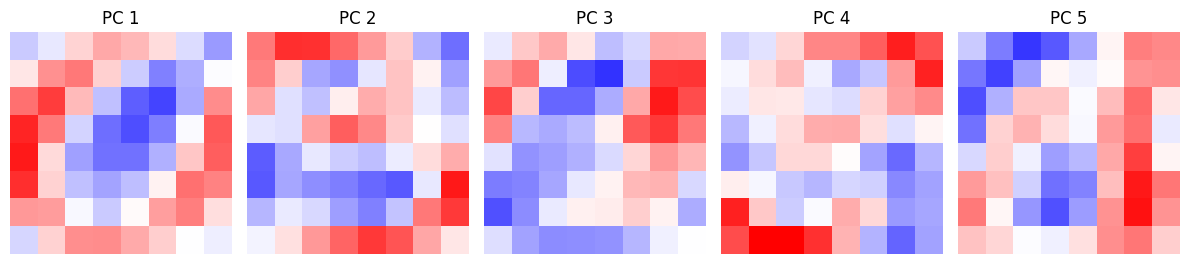